In [ ]:
import kagglehub

# ตัวอย่างการโหลด Dataset ที่แปลงภาพแล้ว (ขนาดเล็กลงเหลือเพียงไม่กี่ GB)
path = kagglehub.dataset_download('awsaf49/vinbigdata-512-image-dataset')
print("Path to images:", path)

Using Colab cache for faster access to the 'vinbigdata-512-image-dataset' dataset.
Path to images: /kaggle/input/vinbigdata-512-image-dataset


In [ ]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import cv2

# กำหนด Path ตามที่โหลดเสร็จ
dataset_path = '/root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1'

# 1. ดูรายการไฟล์และโฟลเดอร์ทั้งหมดใน Dataset
print("รายการไฟล์/โฟลเดอร์ภายใน:")
print(os.listdir(dataset_path))

# 2. ค้นหาโฟลเดอร์รูปภาพ (ปกติมักจะเป็น train หรือ vinbigdata/train)
# ตรวจสอบจำนวนรูปภาพตัวอย่าง
image_files = glob.glob(os.path.join(dataset_path, "**/*.png"), recursive=True)
if not image_files:
    image_files = glob.glob(os.path.join(dataset_path, "**/*.jpg"), recursive=True)

print(f"\nพบรูปภาพทั้งหมด: {len(image_files)} ภาพ")

รายการไฟล์/โฟลเดอร์ภายใน:
['vinbigdata']

พบรูปภาพทั้งหมด: 18000 ภาพ


พบไฟล์ CSV: ['/root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1/vinbigdata/sample_submission.csv', '/root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1/vinbigdata/test.csv', '/root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1/vinbigdata/train.csv']


,image_id,PredictionString
0,002a34c58c5b758217ed1f584ccbcfe9,14 1 0 0 1 1
1,004f33259ee4aef671c2b95d54e4be68,14 1 0 0 1 1
2,008bdde2af2462e86fd373a445d0f4cd,14 1 0 0 1 1
3,009bc039326338823ca3aa84381f17f1,14 1 0 0 1 1
4,00a2145de1886cb9eb88869c85d74080,14 1 0 0 1 1


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3605 (\N{THAI CHARACTER TO TAO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3633 (\N{THAI CHARACTER MAI HAN-AKAT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3618 (\N{THAI CHARACTER YO YAK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, 

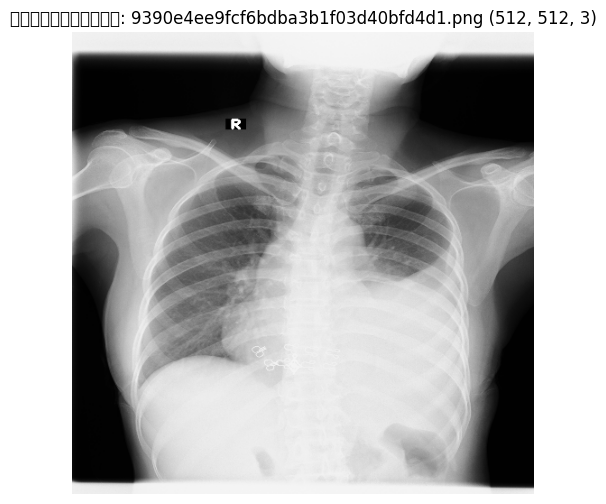

In [ ]:
# 3. โหลดไฟล์ train.csv (หากมีอยู่ใน dataset)
csv_files = glob.glob(os.path.join(dataset_path, "**/*.csv"), recursive=True)
print("พบไฟล์ CSV:", csv_files)

if csv_files:
    df = pd.read_csv(csv_files[0])
    display(df.head())

# 4. ทดลองอ่านและพล็อตภาพตัวอย่าง 1 ภาพ
sample_img_path = image_files[0]
img = cv2.imread(sample_img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title(f"ตัวอย่างภาพ: {os.path.basename(sample_img_path)} {img.shape}")
plt.axis("off")
plt.show()

In [ ]:
# คัดลอกภาพตัวอย่าง 10 ภาพแรกมาไว้ที่โฟลเดอร์ /content/samples
!mkdir -p /content/samples
!cp $(ls /root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1/train/*.png | head -n 10) /content/samples/

ls: cannot access '/root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1/train/*.png': No such file or directory
cp: missing destination file operand after '/content/samples/'
Try 'cp --help' for more information.


กำลังประมวลผลบน: cuda
ใช้ไฟล์ CSV จาก: /root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1/vinbigdata/train.csv
โฟลเดอร์รูปภาพ Train: /root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1/vinbigdata/train
จำนวนรูปที่พบทั้งหมด -> Normal: 10606 ภาพ | Infiltration: 613 ภาพ

สรุปการแบ่งชุดข้อมูล:
- ข้อมูลฝึก (Train): 200 ภาพ (Normal: 100, Infiltration: 100)
- ตรวจสอบ (Val)    : 40 ภาพ (Normal: 20, Infiltration: 20)
- ทดสอบ (Test)     : 100 ภาพ (Normal: 50, Infiltration: 50)

--- เริ่มต้นฝึกสอน Baseline ResNet-50 (Train 200 ภาพ, 7 Epochs) ---
Epoch [1/7] Train Loss: 0.6801 | Train Acc: 0.5750 | Val Loss: 0.6625 | Val Acc: 0.5000
Epoch [2/7] Train Loss: 0.5413 | Train Acc: 0.8950 | Val Loss: 0.6409 | Val Acc: 0.6000
Epoch [3/7] Train Loss: 0.3939 | Train Acc: 0.9750 | Val Loss: 0.5971 | Val Acc: 0.7750
Epoch [4/7] Train Loss: 0.2696 | Train Acc: 0.9750 | Val Loss: 0.5048 | Val Acc: 0.8500
Epoch [5/7] Train Loss: 0.1561 | Train Acc: 0.9800

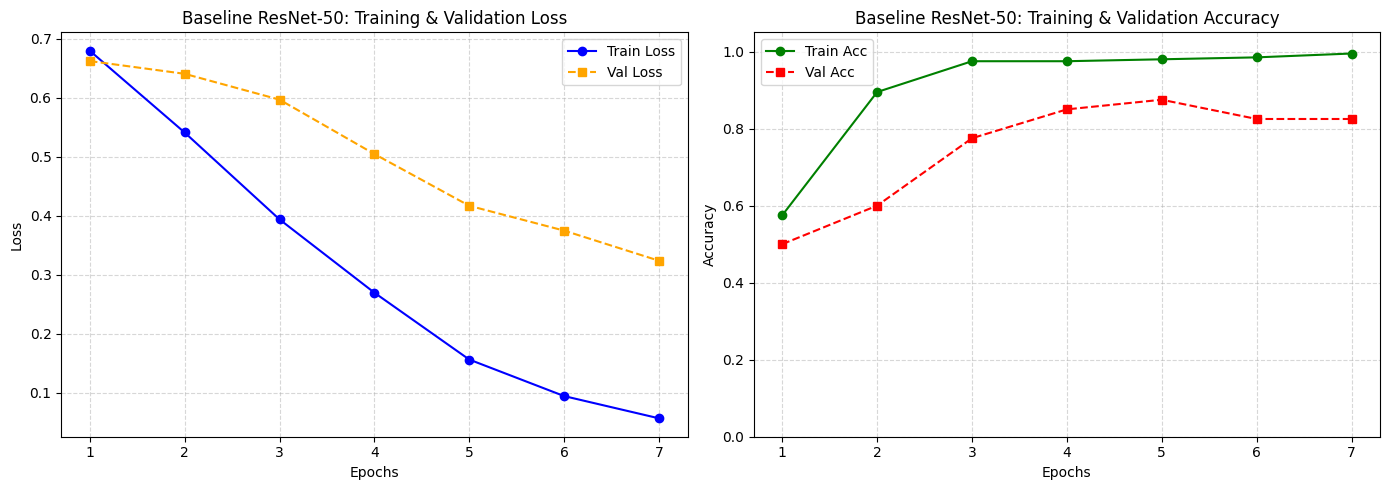

บันทึกภาพกราฟไว้ที่ 'baseline_learning_curves.png'


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# 1. ตรวจสอบการใช้งาน GPU บน Colab
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"กำลังประมวลผลบน: {device}")

# 2. ตั้งค่า Path สำหรับชุดข้อมูล
base_path = '/root/.cache/kagglehub/datasets/awsaf49/vinbigdata-512-image-dataset/versions/1'
train_dir = os.path.join(base_path, 'vinbigdata', 'train')

if not os.path.exists(train_dir):
    train_dir = os.path.join(base_path, 'train')

csv_files = glob.glob(os.path.join(base_path, '**/*train.csv'), recursive=True)
if csv_files:
    csv_path = csv_files[0]
else:
    csv_path = glob.glob(os.path.join(base_path, '**/*.csv'), recursive=True)[0]

print(f"ใช้ไฟล์ CSV จาก: {csv_path}")
print(f"โฟลเดอร์รูปภาพ Train: {train_dir}")

# โหลด Metadata / Labels
df = pd.read_csv(csv_path)

# เตรียม Label สำหรับโจทย์ Binary Classification (Infiltration vs Normal)
if 'class_name' in df.columns:
    df_binary = df[df['class_name'].isin(['Infiltration', 'No finding'])].copy()
    df_binary['target'] = (df_binary['class_name'] == 'Infiltration').astype(int)
else:
    df_binary = df.copy()
    df_binary['target'] = (df_binary['class_id'] != 14).astype(int)

# ลดความซ้ำซ้อนของ image_id และตรวจการมีอยู่ของไฟล์รูปภาพ
df_unique = df_binary.drop_duplicates(subset=['image_id']).copy()
df_unique['img_path'] = df_unique['image_id'].apply(lambda x: os.path.join(train_dir, f"{x}.png"))
df_unique = df_unique[df_unique['img_path'].apply(os.path.exists)].reset_index(drop=True)

# -------------------------------------------------------------
# 3. ปรับให้ชุด Train มีคลาสละ 100 รูปพอดี (Balanced 100:100)
# -------------------------------------------------------------
df_class_0 = df_unique[df_unique['target'] == 0]
df_class_1 = df_unique[df_unique['target'] == 1]

print(f"จำนวนรูปที่พบทั้งหมด -> Normal: {len(df_class_0)} ภาพ | Infiltration: {len(df_class_1)} ภาพ")

# สุ่มคลาสละ 100 รูปสำหรับชุด Train
train_df_0 = df_class_0.sample(n=100, random_state=42)
train_df_1 = df_class_1.sample(n=100, random_state=42)
train_df = pd.concat([train_df_0, train_df_1]).sample(frac=1, random_state=42).reset_index(drop=True)

# จัดสรรข้อมูลที่เหลือสำหรับ Val และ Test
remaining_0 = df_class_0.drop(train_df_0.index)
remaining_1 = df_class_1.drop(train_df_1.index)

test_df_0 = remaining_0.sample(n=50, random_state=42)
test_df_1 = remaining_1.sample(n=50, random_state=42)
test_df = pd.concat([test_df_0, test_df_1]).sample(frac=1, random_state=42).reset_index(drop=True)

remaining_0 = remaining_0.drop(test_df_0.index)
remaining_1 = remaining_1.drop(test_df_1.index)
val_df_0 = remaining_0.sample(n=20, random_state=42)
val_df_1 = remaining_1.sample(n=20, random_state=42)
val_df = pd.concat([val_df_0, val_df_1]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nสรุปการแบ่งชุดข้อมูล:")
print(f"- ข้อมูลฝึก (Train): {len(train_df)} ภาพ (Normal: {(train_df['target']==0).sum()}, Infiltration: {(train_df['target']==1).sum()})")
print(f"- ตรวจสอบ (Val)    : {len(val_df)} ภาพ (Normal: {(val_df['target']==0).sum()}, Infiltration: {(val_df['target']==1).sum()})")
print(f"- ทดสอบ (Test)     : {len(test_df)} ภาพ (Normal: {(test_df['target']==0).sum()}, Infiltration: {(test_df['target']==1).sum()})")

# 4. กำหนด Custom Dataset และ Image Transformation
class CXRDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'img_path']
        image = Image.open(img_path).convert('RGB')
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 5. สร้าง DataLoader ตามไฮเปอร์พารามิเตอร์คงที่ (Batch Size = 32)
train_loader = DataLoader(CXRDataset(train_df, train_transform), batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(CXRDataset(val_df, val_test_transform), batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(CXRDataset(test_df, val_test_transform), batch_size=32, shuffle=False, num_workers=2)

# 6. สร้างโมเดล ResNet-50 Fixed Backbone
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# -------------------------------------------------------------
# 7. Training Loop พร้อมคำนวณ Validation และบันทึกประวัติกราฟ
# -------------------------------------------------------------
num_epochs = 7
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

print(f"\n--- เริ่มต้นฝึกสอน Baseline ResNet-50 (Train 200 ภาพ, {num_epochs} Epochs) ---")

for epoch in range(num_epochs):
    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation Phase
    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data).item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # บันทึกค่าลง history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

# บันทึก Checkpoint
torch.save(model.state_dict(), 'baseline_resnet50.pth')
print("บันทึกโมเดล baseline_resnet50.pth สำเร็จ")

# -------------------------------------------------------------
# 8. พล็อตกราฟ Loss และ Accuracy
# -------------------------------------------------------------
epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(14, 5))

# กราฟ Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], 'o-', label='Train Loss', color='blue')
plt.plot(epochs_range, history['val_loss'], 's--', label='Val Loss', color='orange')
plt.title('Baseline ResNet-50: Training & Validation Loss', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# กราฟ Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], 'o-', label='Train Acc', color='green')
plt.plot(epochs_range, history['val_acc'], 's--', label='Val Acc', color='red')
plt.title('Baseline ResNet-50: Training & Validation Accuracy', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.ylim(0.0, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.savefig('baseline_learning_curves.png', dpi=300)
plt.show()
print("บันทึกภาพกราฟไว้ที่ 'baseline_learning_curves.png'")

# **BASSLINE**

กำลังทำการทดสอบและทำนายผลบนชุดข้อมูลทดสอบ...

 ผลการประเมินโมเดล Baseline ResNet-50 (Raw CXR)
Accuracy  : 0.8400
Precision : 0.8036
Recall    : 0.9000
F1-Score  : 0.8491
ROC-AUC   : 0.9208


<Figure size 600x500 with 0 Axes>

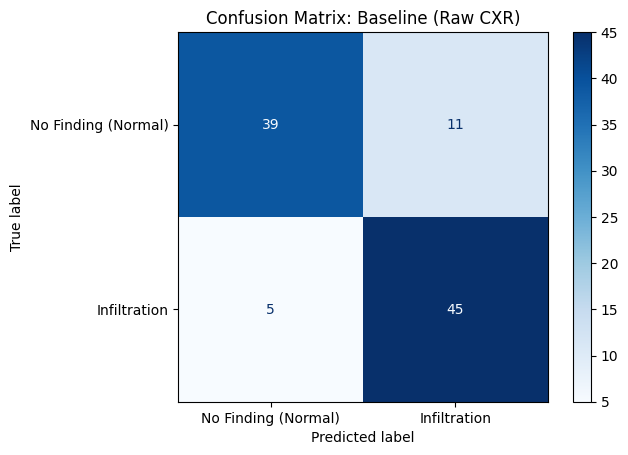

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

# 1. โหลดน้ำหนักโมเดล Baseline ที่บันทึกไว้
model.load_state_dict(torch.load('baseline_resnet50.pth'))
model.eval()

all_preds = []
all_targets = []
all_probs = []

# 2. รันการทำนายบน test_loader
print("กำลังทำการทดสอบและทำนายผลบนชุดข้อมูลทดสอบ...")
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        # คำนวณความน่าจะเป็นของคลาสบวก (Infiltration)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        _, preds = torch.max(outputs, 1)

        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

all_targets = np.array(all_targets)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)

# 3. คำนวณตัวชี้วัดทางการแพทย์
acc = accuracy_score(all_targets, all_preds)
prec = precision_score(all_targets, all_preds, zero_division=0)
rec = recall_score(all_targets, all_preds, zero_division=0)
f1 = f1_score(all_targets, all_preds, zero_division=0)
roc_auc = roc_auc_score(all_targets, all_probs)

print("\n" + "="*50)
print(" ผลการประเมินโมเดล Baseline ResNet-50 (Raw CXR)")
print("="*50)
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print("="*50)

# 4. พล็อต Confusion Matrix ตามรูปแบบตารางการทดลอง
cm = confusion_matrix(all_targets, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Finding (Normal)', 'Infiltration'])

plt.figure(figsize=(6, 5))
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix: Baseline (Raw CXR)")
plt.grid(False)
plt.show()

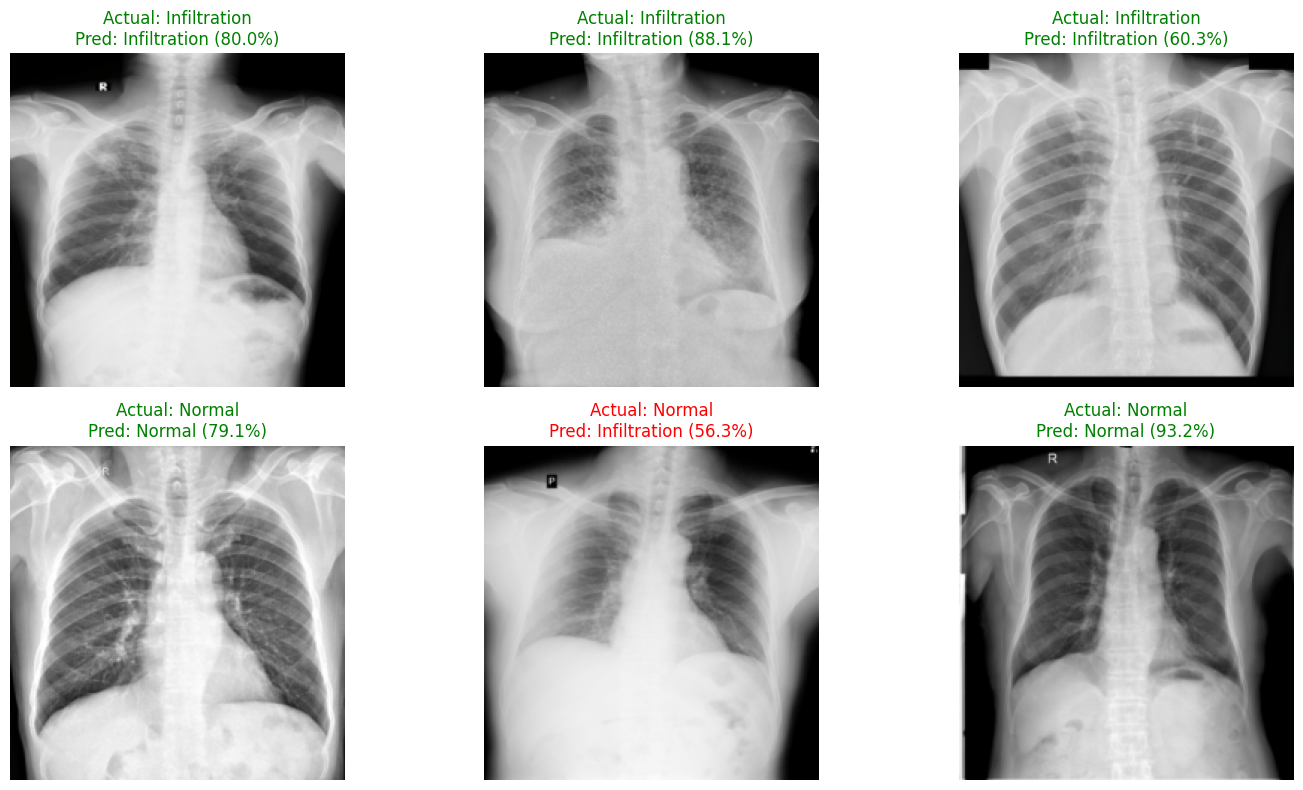

In [ ]:
# ดึง 6 ภาพแรกจาก test_loader มาแสดงผลพร้อมผลทำนาย
data_iter = iter(test_loader)
images, labels = next(data_iter)

with torch.no_grad():
    outputs = model(images.to(device))
    probs = torch.softmax(outputs, dim=1)
    _, preds = torch.max(outputs, 1)

class_names = ['Normal', 'Infiltration']

plt.figure(figsize=(15, 8))
for i in range(min(6, len(images))):
    plt.subplot(2, 3, i + 1)
    # แปลง Tensor กลับเป็นภาพปกติ
    img_display = images[i].permute(1, 2, 0).cpu().numpy()
    img_display = img_display * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
    img_display = np.clip(img_display, 0, 1)

    actual_label = class_names[labels[i].item()]
    predicted_label = class_names[preds[i].item()]
    confidence = probs[i][preds[i].item()].item() * 100

    color = 'green' if actual_label == predicted_label else 'red'

    plt.imshow(img_display)
    plt.title(f"Actual: {actual_label}\nPred: {predicted_label} ({confidence:.1f}%)", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

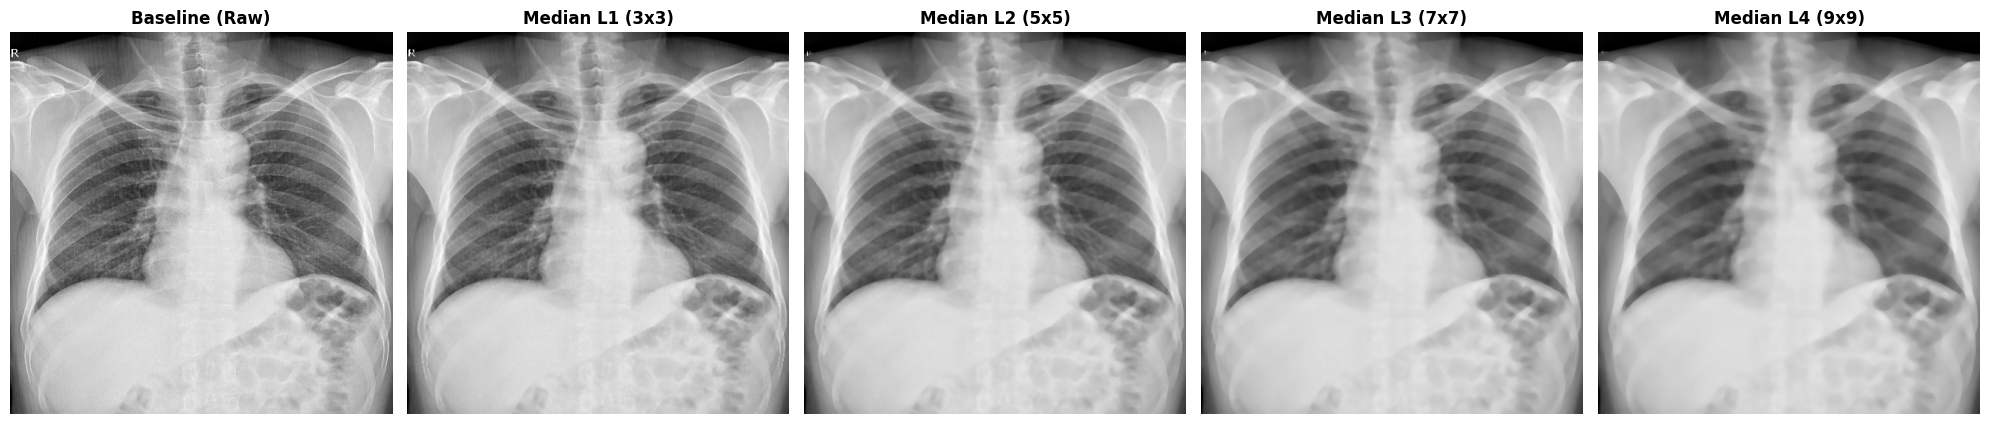

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. ฟังก์ชันประมวลผล Median Filter แต่ละระดับ
def apply_median_filter(image_pil, level='L1'):
    # แปลงเป็น Grayscale NumPy array
    img_gray = np.array(image_pil.convert('L'))

    if level == 'Baseline':
        processed = img_gray
    elif level == 'L1':
        processed = cv2.medianBlur(img_gray, 3)  # Kernel 3x3
    elif level == 'L2':
        processed = cv2.medianBlur(img_gray, 5)  # Kernel 5x5
    elif level == 'L3':
        processed = cv2.medianBlur(img_gray, 7)  # Kernel 7x7
    elif level == 'L4':
        processed = cv2.medianBlur(img_gray, 9)  # Kernel 9x9 (เพิ่มเติม)
    else:
        processed = img_gray

    return Image.fromarray(processed).convert('RGB')

# 2. ดึงภาพตัวอย่างจากชุด Train มาทดสอบแสดงผล
sample_img_path = train_df.iloc[0]['img_path']
raw_sample = Image.open(sample_img_path)

# ประมวลผลภาพในแต่ละระดับ
img_base = apply_median_filter(raw_sample, 'Baseline')
img_l1 = apply_median_filter(raw_sample, 'L1')
img_l2 = apply_median_filter(raw_sample, 'L2')
img_l3 = apply_median_filter(raw_sample, 'L3')
img_l4 = apply_median_filter(raw_sample, 'L4')

# 3. พล็อตเปรียบเทียบความแตกต่าง
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
titles = [
    'Baseline (Raw)',
    'Median L1 (3x3)',
    'Median L2 (5x5)',
    'Median L3 (7x7)',
    'Median L4 (9x9)'
]
images = [img_base, img_l1, img_l2, img_l3, img_l4]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
class DenoisedCXRDataset(Dataset):
    def __init__(self, dataframe, filter_level='L1', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.filter_level = filter_level
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'img_path']
        image = Image.open(img_path).convert('RGB')

        # นำภาพไปผ่าน Median Filter ตามระดับที่กำหนดก่อน
        image = apply_median_filter(image, level=self.filter_level)
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# ตัวอย่างการสร้าง DataLoader สำหรับ Median Filter L1
train_loader_median_l1 = DataLoader(
    DenoisedCXRDataset(train_df, filter_level='L1', transform=train_transform),
    batch_size=32, shuffle=True, num_workers=2
)
val_loader_median_l1 = DataLoader(
    DenoisedCXRDataset(val_df, filter_level='L1', transform=val_test_transform),
    batch_size=32, shuffle=False, num_workers=2
)

# **Median Filter L1 - L4**

 เริ่มการทดลองฝึกสอน Median Filter Pipeline (L1 - L4)

>>> [กำลังเริ่มการทดลอง: Median Filter L1] <<<
Epoch [01/07] Loss: 0.6846 | Train Acc: 0.5450
Epoch [04/07] Loss: 0.3042 | Train Acc: 0.9600
Epoch [07/07] Loss: 0.0560 | Train Acc: 0.9950

>>> [กำลังเริ่มการทดลอง: Median Filter L2] <<<
Epoch [01/07] Loss: 0.6869 | Train Acc: 0.5450
Epoch [04/07] Loss: 0.2719 | Train Acc: 0.9800
Epoch [07/07] Loss: 0.0490 | Train Acc: 1.0000

>>> [กำลังเริ่มการทดลอง: Median Filter L3] <<<
Epoch [01/07] Loss: 0.6868 | Train Acc: 0.5350
Epoch [04/07] Loss: 0.2834 | Train Acc: 0.9850
Epoch [07/07] Loss: 0.0790 | Train Acc: 0.9900

>>> [กำลังเริ่มการทดลอง: Median Filter L4] <<<
Epoch [01/07] Loss: 0.6865 | Train Acc: 0.5500
Epoch [04/07] Loss: 0.2927 | Train Acc: 0.9800
Epoch [07/07] Loss: 0.0629 | Train Acc: 0.9900

 สรุปผลการประเมินโมเดล Median Filter แต่ละระดับ (Classification Table)


,สภาวะการทดลอง,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Median Filter L1,0.7800,0.8684,0.6600,0.7500,0.8440
1,Median Filter L2,0.8200,0.7759,0.9000,0.8333,0.9388
2,Median Filter L3,0.8300,0.8113,0.8600,0.8350,0.9128
3,Median Filter L4,0.8000,0.7586,0.8800,0.8148,0.8968


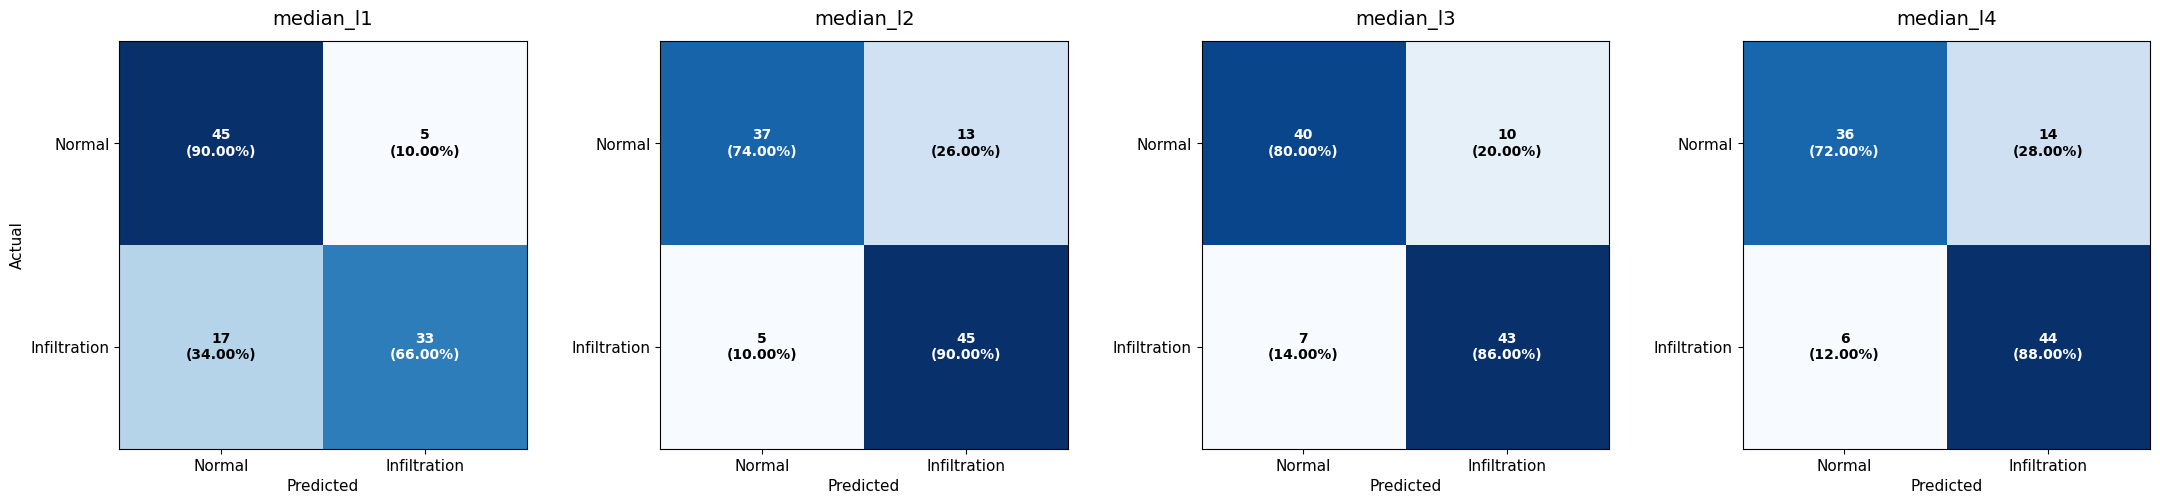

บันทึกภาพ Confusion Matrix เรียบร้อยแล้วที่ 'confusion_matrices_median_L1_L4.png'


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# 1. ฟังก์ชันตัวกรอง Median Filter ตามระดับ Kernel
def apply_median_filter(pil_img, level='L1'):
    img_gray = np.array(pil_img.convert('L'))
    kernel_sizes = {'L1': 3, 'L2': 5, 'L3': 7, 'L4': 9}
    ksize = kernel_sizes.get(level, 3)
    filtered = cv2.medianBlur(img_gray, ksize)
    return Image.fromarray(filtered).convert('RGB')

# 2. Custom Dataset รองรับการทำ Median Filter
class DenoisedCXRDataset(Dataset):
    def __init__(self, dataframe, filter_level='L1', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.filter_level = filter_level
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'img_path']
        image = Image.open(img_path).convert('RGB')
        image = apply_median_filter(image, self.filter_level)
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# 3. เตรียมการทดลองวนลูป L1 ถึง L4
filter_levels = ['L1', 'L2', 'L3', 'L4']
results = []
confusion_matrices = {}

print("==================================================")
print(" เริ่มการทดลองฝึกสอน Median Filter Pipeline (L1 - L4)")
print("==================================================")

for level in filter_levels:
    print(f"\n>>> [กำลังเริ่มการทดลอง: Median Filter {level}] <<<")

    # สร้าง DataLoaders เฉพาะของระดับนั้น
    lvl_train_loader = DataLoader(
        DenoisedCXRDataset(train_df, filter_level=level, transform=train_transform),
        batch_size=32, shuffle=True, num_workers=2
    )
    lvl_test_loader = DataLoader(
        DenoisedCXRDataset(test_df, filter_level=level, transform=val_test_transform),
        batch_size=32, shuffle=False, num_workers=2
    )

    # รีเซ็ตสถาปัตยกรรมโมเดล ResNet-50 ใหม่ทุกรอบเพื่อ Fair Comparison
    lvl_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    lvl_model.fc = nn.Linear(lvl_model.fc.in_features, 2)
    lvl_model = lvl_model.to(device)

    lvl_criterion = nn.CrossEntropyLoss()
    lvl_optimizer = torch.optim.Adam(lvl_model.parameters(), lr=1e-4)

    # ฝึกสอนโมเดล 7 Epochs
    lvl_model.train()
    for epoch in range(7):
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in lvl_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            lvl_optimizer.zero_grad()
            outputs = lvl_model(imgs)
            loss = lvl_criterion(outputs, lbls)
            loss.backward()
            lvl_optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == lbls.data).item()
            total += lbls.size(0)

        if (epoch + 1) in [1, 4, 7]:
            print(f"Epoch [{epoch+1:02d}/07] Loss: {running_loss/total:.4f} | Train Acc: {correct/total:.4f}")

    # บันทึก Checkpoint
    model_save_path = f"median_{level.lower()}_resnet50.pth"
    torch.save(lvl_model.state_dict(), model_save_path)

    # 4. ทดสอบและประเมินผลบนชุดทดสอบมาตรฐาน (Test Set 100 เคส)
    lvl_model.eval()
    all_preds, all_targets, all_probs = [], [], []
    with torch.no_grad():
        for imgs, lbls in lvl_test_loader:
            imgs = imgs.to(device)
            outputs = lvl_model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(lbls.numpy())

    all_targets = np.array(all_targets)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    # คำนวณตัวชี้วัด
    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    roc = roc_auc_score(all_targets, all_probs)

    results.append({
        'สภาวะการทดลอง': f'Median Filter {level}',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

    # เก็บ Confusion Matrix
    confusion_matrices[level] = confusion_matrix(all_targets, all_preds)

# -------------------------------------------------------------
# 5. แสดงตารางสรุปผลลัพธ์การทดลอง
# -------------------------------------------------------------
df_results = pd.DataFrame(results)
print("\n" + "="*70)
print(" สรุปผลการประเมินโมเดล Median Filter แต่ละระดับ (Classification Table)")
print("="*70)
display(df_results.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))

# -------------------------------------------------------------
# 6. พล็อต Confusion Matrices เรียงต่อกัน 4 ระดับ
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_labels = ['Normal', 'Infiltration']

for idx, level in enumerate(filter_levels):
    cm = confusion_matrices[level]
    ax = axes[idx]

    # วาดตาราง Heatmap สีฟ้าตามรูปแบบตารางรายงาน
    cax = ax.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    ax.set_title(f'median_{level.lower()}', fontsize=14, pad=12)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels, fontsize=11)
    ax.set_yticklabels(class_labels, fontsize=11)
    ax.set_xlabel('Predicted', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Actual', fontsize=11)

    # ใส่ตัวเลขจำนวนและเปอร์เซ็นต์ในแต่ละช่อง
    for i in range(2):
        row_sum = cm[i].sum()
        for j in range(2):
            count = cm[i, j]
            pct = (count / row_sum * 100) if row_sum > 0 else 0
            text_color = "white" if count > (cm.max() / 2) else "black"
            ax.text(j, i, f"{count}\n({pct:.2f}%)", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices_median_L1_L4.png', dpi=300)
plt.show()
print("บันทึกภาพ Confusion Matrix เรียบร้อยแล้วที่ 'confusion_matrices_median_L1_L4.png'")

# **CLAHE + DWT (L1 – L4)**

 เริ่มการทดลองฝึกสอน CLAHE + DWT Pipeline (L1 - L4)

>>> [กำลังเริ่มการทดลอง: CLAHE + DWT L1] <<<
Epoch [01/07] Loss: 0.6887 | Train Acc: 0.5650
Epoch [04/07] Loss: 0.2636 | Train Acc: 0.9800
Epoch [07/07] Loss: 0.0487 | Train Acc: 0.9950
บันทึกโมเดล clahe_dwt_l1_resnet50.pth เรียบร้อย

>>> [กำลังเริ่มการทดลอง: CLAHE + DWT L2] <<<
Epoch [01/07] Loss: 0.6950 | Train Acc: 0.5050
Epoch [04/07] Loss: 0.2954 | Train Acc: 0.9750
Epoch [07/07] Loss: 0.0459 | Train Acc: 1.0000
บันทึกโมเดล clahe_dwt_l2_resnet50.pth เรียบร้อย

>>> [กำลังเริ่มการทดลอง: CLAHE + DWT L3] <<<
Epoch [01/07] Loss: 0.6668 | Train Acc: 0.6500
Epoch [04/07] Loss: 0.2212 | Train Acc: 0.9850
Epoch [07/07] Loss: 0.0451 | Train Acc: 0.9950
บันทึกโมเดล clahe_dwt_l3_resnet50.pth เรียบร้อย

>>> [กำลังเริ่มการทดลอง: CLAHE + DWT L4] <<<
Epoch [01/07] Loss: 0.6791 | Train Acc: 0.5800
Epoch [04/07] Loss: 0.2792 | Train Acc: 0.9700
Epoch [07/07] Loss: 0.0636 | Train Acc: 0.9900
บันทึกโมเดล clahe_dwt_l4_resnet50.pth เรียบร้อย

 ผลการป

,สภาวะการทดลอง,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,CLAHE + DWT L1,0.8800,0.8800,0.8800,0.8800,0.9696
1,CLAHE + DWT L2,0.8400,0.8148,0.8800,0.8462,0.9312
2,CLAHE + DWT L3,0.8500,0.8571,0.8400,0.8485,0.8940
3,CLAHE + DWT L4,0.8500,0.8571,0.8400,0.8485,0.8996


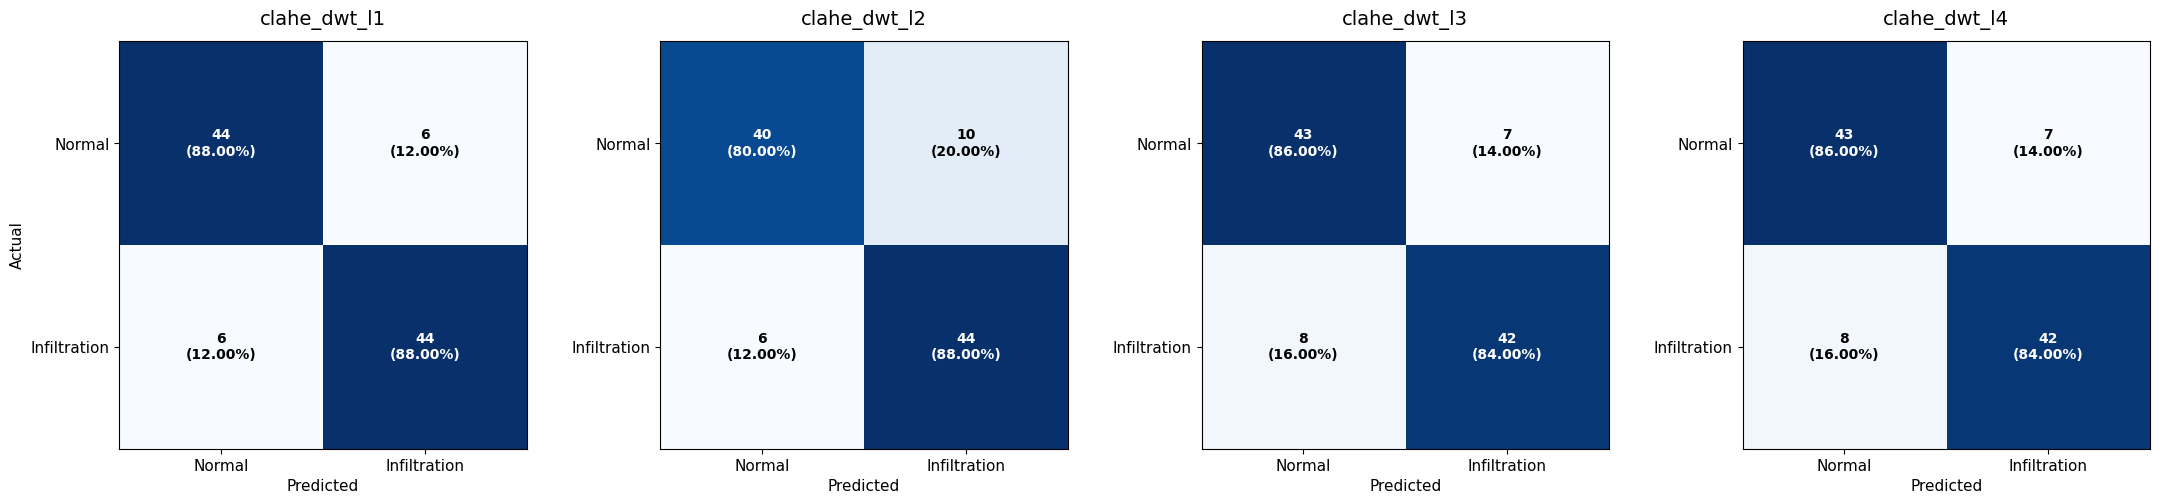

บันทึกภาพ Confusion Matrix ที่ 'confusion_matrices_clahe_dwt_L1_L4.png'


In [ ]:
import os
import cv2
import pywt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# 1. ฟังก์ชัน CLAHE + DWT ตามระเบียบวิธีวิจัย (Wavelet: db1)
def apply_clahe_dwt(pil_img, level='L1'):
    img_np = np.array(pil_img.convert('L'), dtype=np.uint8)

    # พารามิเตอร์ของแต่ละระดับ L1 - L4
    params = {
        'L1': {'clip_limit': 1.0, 'thresh_ratio': 0.05},
        'L2': {'clip_limit': 2.0, 'thresh_ratio': 0.10},
        'L3': {'clip_limit': 3.0, 'thresh_ratio': 0.20},
        'L4': {'clip_limit': 4.0, 'thresh_ratio': 0.30}
    }
    cfg = params.get(level, params['L1'])

    # ขั้นตอนที่ 1: Contrast Limited Adaptive Histogram Equalization (CLAHE)
    clahe = cv2.createCLAHE(clipLimit=cfg['clip_limit'], tileGridSize=(8, 8))
    enhanced_img = clahe.apply(img_np)

    # ขั้นตอนที่ 2: Discrete Wavelet Transform (2D DWT - Wavelet 'db1')
    coeffs2 = pywt.dwt2(enhanced_img.astype(np.float32), 'db1')
    LL, (LH, HL, HH) = coeffs2

    # กรองสัมประสิทธิ์ความถี่สูงด้วย Soft Thresholding
    threshold = cfg['thresh_ratio'] * np.max([np.abs(LH), np.abs(HL), np.abs(HH)])
    LH_thresh = pywt.threshold(LH, threshold, mode='soft')
    HL_thresh = pywt.threshold(HL, threshold, mode='soft')
    HH_thresh = pywt.threshold(HH, threshold, mode='soft')

    # ขั้นตอนที่ 3: สังเคราะห์ภาพกลับ (Inverse 2D DWT)
    reconstructed = pywt.idwt2((LL, (LH_thresh, HL_thresh, HH_thresh)), 'db1')
    reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)

    return Image.fromarray(reconstructed).convert('RGB')

# 2. Custom Dataset สำหรับ CLAHE + DWT
class ClaheDwtCXRDataset(Dataset):
    def __init__(self, dataframe, filter_level='L1', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.filter_level = filter_level
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'img_path']
        image = Image.open(img_path).convert('RGB')

        # ส่งผ่านอัลกอริทึม CLAHE + DWT
        image = apply_clahe_dwt(image, self.filter_level)
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# 3. เริ่มกระบวนการทดลองวนลูป L1 ถึง L4
filter_levels = ['L1', 'L2', 'L3', 'L4']
results = []
confusion_matrices = {}

print("======================================================")
print(" เริ่มการทดลองฝึกสอน CLAHE + DWT Pipeline (L1 - L4)")
print("======================================================")

for level in filter_levels:
    print(f"\n>>> [กำลังเริ่มการทดลอง: CLAHE + DWT {level}] <<<")

    # DataLoader ประจำระดับ
    lvl_train_loader = DataLoader(
        ClaheDwtCXRDataset(train_df, filter_level=level, transform=train_transform),
        batch_size=32, shuffle=True, num_workers=2
    )
    lvl_test_loader = DataLoader(
        ClaheDwtCXRDataset(test_df, filter_level=level, transform=val_test_transform),
        batch_size=32, shuffle=False, num_workers=2
    )

    # รีเซ็ตโครงข่าย ResNet-50 ใหม่ทุกรอบเพื่อความยุติธรรม (Fair Comparison)
    lvl_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    lvl_model.fc = nn.Linear(lvl_model.fc.in_features, 2)
    lvl_model = lvl_model.to(device)

    lvl_criterion = nn.CrossEntropyLoss()
    lvl_optimizer = torch.optim.Adam(lvl_model.parameters(), lr=1e-4)

    # ฝึกสอน 7 Epochs
    lvl_model.train()
    for epoch in range(7):
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in lvl_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            lvl_optimizer.zero_grad()
            outputs = lvl_model(imgs)
            loss = lvl_criterion(outputs, lbls)
            loss.backward()
            lvl_optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == lbls.data).item()
            total += lbls.size(0)

        if (epoch + 1) in [1, 4, 7]:
            print(f"Epoch [{epoch+1:02d}/07] Loss: {running_loss/total:.4f} | Train Acc: {correct/total:.4f}")

    # บันทึก Checkpoint โมเดล
    save_name = f"clahe_dwt_{level.lower()}_resnet50.pth"
    torch.save(lvl_model.state_dict(), save_name)
    print(f"บันทึกโมเดล {save_name} เรียบร้อย")

    # 4. ทดสอบและประเมินผลบนชุดทดสอบมาตรฐาน (Test Set 100 เคส)
    lvl_model.eval()
    all_preds, all_targets, all_probs = [], [], []
    with torch.no_grad():
        for imgs, lbls in lvl_test_loader:
            imgs = imgs.to(device)
            outputs = lvl_model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(lbls.numpy())

    all_targets = np.array(all_targets)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    # คำนวณ Metric ทางการแพทย์
    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    roc = roc_auc_score(all_targets, all_probs)

    results.append({
        'สภาวะการทดลอง': f'CLAHE + DWT {level}',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

    confusion_matrices[level] = confusion_matrix(all_targets, all_preds)

# -------------------------------------------------------------
# 5. แสดงตารางสรุปผลลัพธ์
# -------------------------------------------------------------
df_results = pd.DataFrame(results)
print("\n" + "="*70)
print(" ผลการประเมินการจำแนกโรคกลุ่ม CLAHE + DWT (L1 - L4)")
print("="*70)
display(df_results.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))

# -------------------------------------------------------------
# 6. พล็อต Confusion Matrices 4 ระดับเปรียบเทียบกัน
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_labels = ['Normal', 'Infiltration']

for idx, level in enumerate(filter_levels):
    cm = confusion_matrices[level]
    ax = axes[idx]

    cax = ax.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    ax.set_title(f'clahe_dwt_{level.lower()}', fontsize=14, pad=12)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels, fontsize=11)
    ax.set_yticklabels(class_labels, fontsize=11)
    ax.set_xlabel('Predicted', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Actual', fontsize=11)

    for i in range(2):
        row_sum = cm[i].sum()
        for j in range(2):
            count = cm[i, j]
            pct = (count / row_sum * 100) if row_sum > 0 else 0
            text_color = "white" if count > (cm.max() / 2) else "black"
            ax.text(j, i, f"{count}\n({pct:.2f}%)", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices_clahe_dwt_L1_L4.png', dpi=300)
plt.show()
print("บันทึกภาพ Confusion Matrix ที่ 'confusion_matrices_clahe_dwt_L1_L4.png'")

# **DAE + CLAHE L1 - L4**

--- กำลังฝึกสอนโมเดล DAE เบื้องต้น ---
DAE Pretrain Epoch [1/5] Loss: 0.02747
DAE Pretrain Epoch [2/5] Loss: 0.00526
DAE Pretrain Epoch [3/5] Loss: 0.00331
DAE Pretrain Epoch [4/5] Loss: 0.00255
DAE Pretrain Epoch [5/5] Loss: 0.00247
กำลัง Pre-process ภาพชุด train (200 ภาพ)...
กำลัง Pre-process ภาพชุด test (100 ภาพ)...
แคชภาพ DAE + CLAHE ทั้งหมดเรียบร้อยแล้ว!

 เริ่มการทดลองฝึกสอน DAE + CLAHE Pipeline (L1 - L4)

>>> [กำลังเริ่มการทดลอง: DAE + CLAHE L1] <<<
Epoch [01/07] Loss: 0.6782 | Train Acc: 0.6100
Epoch [04/07] Loss: 0.4006 | Train Acc: 0.9350
Epoch [07/07] Loss: 0.0926 | Train Acc: 0.9900

>>> [กำลังเริ่มการทดลอง: DAE + CLAHE L2] <<<
Epoch [01/07] Loss: 0.6858 | Train Acc: 0.5800
Epoch [04/07] Loss: 0.3856 | Train Acc: 0.9700
Epoch [07/07] Loss: 0.0947 | Train Acc: 0.9900

>>> [กำลังเริ่มการทดลอง: DAE + CLAHE L3] <<<
Epoch [01/07] Loss: 0.6880 | Train Acc: 0.5400
Epoch [04/07] Loss: 0.3727 | Train Acc: 0.9600
Epoch [07/07] Loss: 0.0947 | Train Acc: 0.9900

>>> [กำลังเริ่มการทดลอง

,สภาวะการทดลอง,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,DAE + CLAHE L1,0.8300,0.7797,0.9200,0.8440,0.8940
1,DAE + CLAHE L2,0.7700,0.7368,0.8400,0.7850,0.8580
2,DAE + CLAHE L3,0.7800,0.7593,0.8200,0.7885,0.8532
3,DAE + CLAHE L4,0.7700,0.8000,0.7200,0.7579,0.8388


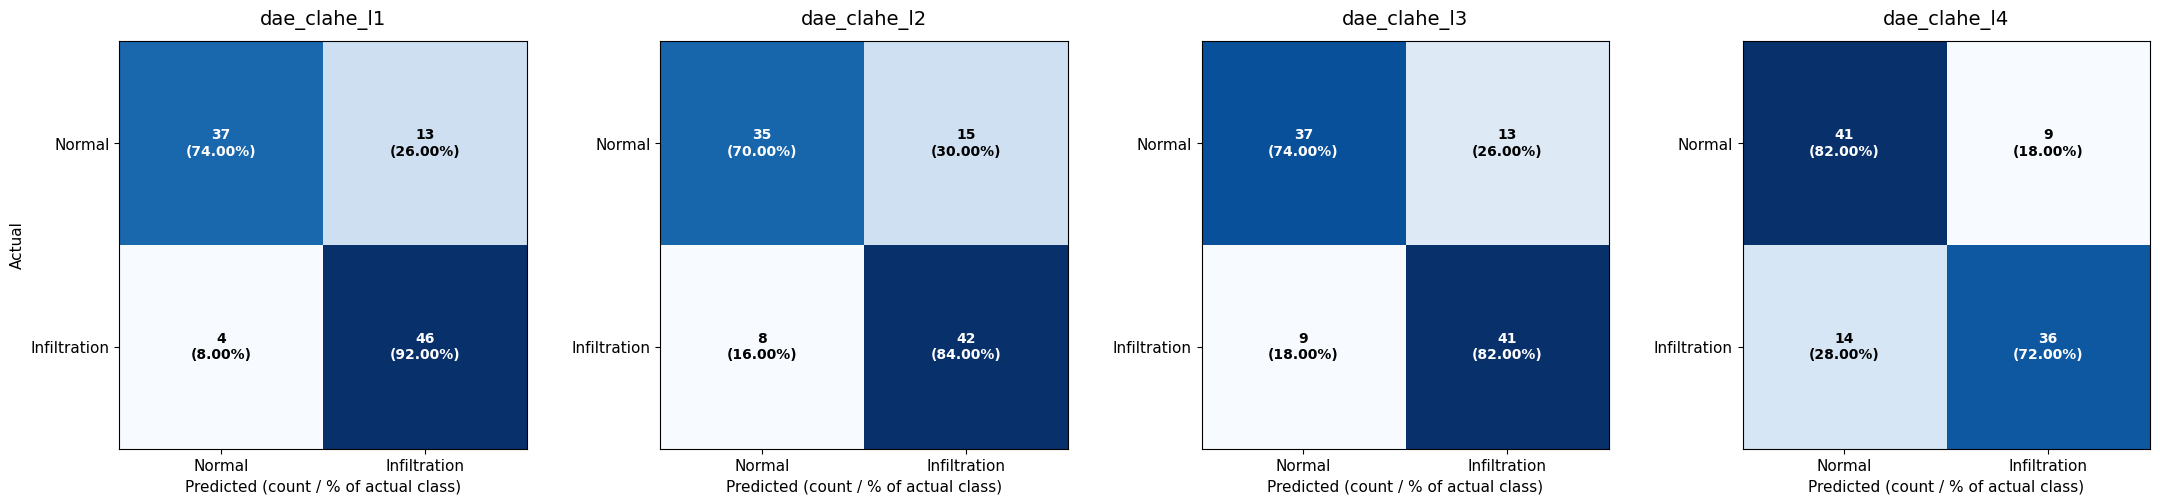

บันทึกภาพ Confusion Matrix สำเร็จที่ 'confusion_matrices_dae_clahe_L1_L4.png'


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# -------------------------------------------------------------
# 1. โครงสร้าง Denoising Autoencoder (DAE)
# -------------------------------------------------------------
class ConvDAE(nn.Module):
    def __init__(self):
        super(ConvDAE, self).__init__()
        self.enc1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        self.enc2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        self.dec1 = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.dec2 = nn.Sequential(
            nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2),
            nn.Sigmoid()
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        d1 = self.dec1(e2)
        out = self.dec2(d1)
        return out

# ฝึกสอน DAE แบบย่อด้วย Gaussian Noise (Unsupervised)
print("--- กำลังฝึกสอนโมเดล DAE เบื้องต้น ---")
dae_model = ConvDAE().to(device)
dae_optimizer = torch.optim.Adam(dae_model.parameters(), lr=1e-3)
dae_criterion = nn.MSELoss()

class DAETrainingDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)
        self.resize = transforms.Resize((224, 224))
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img = Image.open(self.df.loc[idx, 'img_path']).convert('L')
        clean_tensor = self.to_tensor(self.resize(img))
        noise = torch.randn_like(clean_tensor) * 0.08
        noisy_tensor = torch.clamp(clean_tensor + noise, 0., 1.)
        return noisy_tensor, clean_tensor

# ใช้ num_workers=0 สำหรับการเทรน DAE เพื่อป้องกัน CUDA subprocess issue
dae_loader = DataLoader(DAETrainingDataset(train_df), batch_size=16, shuffle=True, num_workers=0)

dae_model.train()
for d_epoch in range(5):
    d_loss = 0.0
    for noisy_imgs, clean_imgs in dae_loader:
        noisy_imgs, clean_imgs = noisy_imgs.to(device), clean_imgs.to(device)
        dae_optimizer.zero_grad()
        recon = dae_model(noisy_imgs)
        loss = dae_criterion(recon, clean_imgs)
        loss.backward()
        dae_optimizer.step()
        d_loss += loss.item() * noisy_imgs.size(0)
    print(f"DAE Pretrain Epoch [{d_epoch+1}/5] Loss: {d_loss/len(train_df):.5f}")

dae_model.eval()

# -------------------------------------------------------------
# 2. ฟังก์ชันประมวลผล DAE + CLAHE (Pre-process ล่วงหน้า)
# -------------------------------------------------------------
clip_limits = {'L1': 2.0, 'L2': 4.0, 'L3': 8.0, 'L4': 10.0}

def preprocess_and_save_dataset(df_subset, subset_name):
    """รัน DAE บน GPU ล่วงหน้าครั้งเดียวและสร้างภาพ CLAHE แต่ละระดับลงโฟลเดอร์"""
    to_tensor = transforms.ToTensor()
    resize = transforms.Resize((224, 224))

    # สร้างโฟลเดอร์เก็บภาพที่ประมวลผลแล้ว
    for lvl in ['L1', 'L2', 'L3', 'L4']:
        os.makedirs(f"/content/dae_cache/{subset_name}/{lvl}", exist_ok=True)

    print(f"กำลัง Pre-process ภาพชุด {subset_name} ({len(df_subset)} ภาพ)...")
    with torch.no_grad():
        for _, row in df_subset.iterrows():
            img_id = row['image_id']
            img = Image.open(row['img_path']).convert('L')
            img_t = to_tensor(resize(img)).unsqueeze(0).to(device)

            # กรอง Noise ด้วย DAE
            denoised_t = dae_model(img_t).squeeze().cpu().numpy()
            denoised_np = np.clip(denoised_t * 255.0, 0, 255).astype(np.uint8)

            # ประยุกต์ใช้ CLAHE ตามระดับ Clip Limit
            for lvl, clip_val in clip_limits.items():
                clahe = cv2.createCLAHE(clipLimit=clip_val, tileGridSize=(8, 8))
                enhanced_np = clahe.apply(denoised_np)
                save_path = f"/content/dae_cache/{subset_name}/{lvl}/{img_id}.png"
                cv2.imwrite(save_path, enhanced_np)

# ทำแคชล่วงหน้าสำหรับทั้ง Train และ Test
preprocess_and_save_dataset(train_df, "train")
preprocess_and_save_dataset(test_df, "test")
print("แคชภาพ DAE + CLAHE ทั้งหมดเรียบร้อยแล้ว!")

# -------------------------------------------------------------
# 3. Custom Dataset โหลดภาพจากแคชโดยตรง (ทำงานร่วมกับ num_workers=2 ได้ 100%)
# -------------------------------------------------------------
class CachedDaeClaheDataset(Dataset):
    def __init__(self, dataframe, subset_name="train", level='L1', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.subset_name = subset_name
        self.level = level
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_id = self.df.loc[idx, 'image_id']
        cached_path = f"/content/dae_cache/{self.subset_name}/{self.level}/{img_id}.png"
        image = Image.open(cached_path).convert('RGB')
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# -------------------------------------------------------------
# 4. ฝึกสอน ResNet-50 เปรียบเทียบ DAE + CLAHE (L1 - L4)
# -------------------------------------------------------------
filter_levels = ['L1', 'L2', 'L3', 'L4']
results = []
confusion_matrices = {}

print("\n========================================================")
print(" เริ่มการทดลองฝึกสอน DAE + CLAHE Pipeline (L1 - L4)")
print("========================================================")

for level in filter_levels:
    print(f"\n>>> [กำลังเริ่มการทดลอง: DAE + CLAHE {level}] <<<")

    lvl_train_loader = DataLoader(
        CachedDaeClaheDataset(train_df, "train", level=level, transform=train_transform),
        batch_size=32, shuffle=True, num_workers=2
    )
    lvl_test_loader = DataLoader(
        CachedDaeClaheDataset(test_df, "test", level=level, transform=val_test_transform),
        batch_size=32, shuffle=False, num_workers=2
    )

    lvl_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    lvl_model.fc = nn.Linear(lvl_model.fc.in_features, 2)
    lvl_model = lvl_model.to(device)

    lvl_criterion = nn.CrossEntropyLoss()
    lvl_optimizer = torch.optim.Adam(lvl_model.parameters(), lr=1e-4)

    # เทรน 7 Epochs
    lvl_model.train()
    for epoch in range(7):
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in lvl_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            lvl_optimizer.zero_grad()
            outputs = lvl_model(imgs)
            loss = lvl_criterion(outputs, lbls)
            loss.backward()
            lvl_optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == lbls.data).item()
            total += lbls.size(0)

        if (epoch + 1) in [1, 4, 7]:
            print(f"Epoch [{epoch+1:02d}/07] Loss: {running_loss/total:.4f} | Train Acc: {correct/total:.4f}")

    # บันทึก Checkpoint
    save_name = f"dae_clahe_{level.lower()}_resnet50.pth"
    torch.save(lvl_model.state_dict(), save_name)

    # ประเมินผลบนชุดทดสอบมาตรฐาน (Test Set 100 เคส)
    lvl_model.eval()
    all_preds, all_targets, all_probs = [], [], []
    with torch.no_grad():
        for imgs, lbls in lvl_test_loader:
            imgs = imgs.to(device)
            outputs = lvl_model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(lbls.numpy())

    all_targets = np.array(all_targets)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    roc = roc_auc_score(all_targets, all_probs)

    results.append({
        'สภาวะการทดลอง': f'DAE + CLAHE {level}',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

    confusion_matrices[level] = confusion_matrix(all_targets, all_preds)

# -------------------------------------------------------------
# 5. แสดงผลตารางสรุป Metric ทางการแพทย์
# -------------------------------------------------------------
df_results = pd.DataFrame(results)
print("\n" + "="*70)
print(" สรุปผลการประเมินการจำแนกโรคกลุ่ม DAE + CLAHE (L1 - L4)")
print("="*70)
display(df_results.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))

# -------------------------------------------------------------
# 6. พล็อต Confusion Matrices 4 ช่อง
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_labels = ['Normal', 'Infiltration']

for idx, level in enumerate(filter_levels):
    cm = confusion_matrices[level]
    ax = axes[idx]

    ax.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    ax.set_title(f'dae_clahe_{level.lower()}', fontsize=14, pad=12)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels, fontsize=11)
    ax.set_yticklabels(class_labels, fontsize=11)
    ax.set_xlabel('Predicted (count / % of actual class)', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Actual', fontsize=11)

    for i in range(2):
        row_sum = cm[i].sum()
        for j in range(2):
            count = cm[i, j]
            pct = (count / row_sum * 100) if row_sum > 0 else 0
            text_color = "white" if count > (cm.max() / 2) else "black"
            ax.text(j, i, f"{count}\n({pct:.2f}%)", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices_dae_clahe_L1_L4.png', dpi=300)
plt.show()
print("บันทึกภาพ Confusion Matrix สำเร็จที่ 'confusion_matrices_dae_clahe_L1_L4.png'")

# **DWT**

กำลังบันทึกแคช DWT สำหรับชุด train (200 ภาพ)...
กำลังบันทึกแคช DWT สำหรับชุด test (100 ภาพ)...
แคชชุดข้อมูล DWT L1 - L4 เสร็จสมบูรณ์!

 เริ่มการทดลองฝึกสอน Pure DWT Pipeline (L1 - L4)

>>> [กำลังเริ่มการทดลอง: Pure DWT L1] <<<
Epoch [01/07] Loss: 0.6854 | Train Acc: 0.5700
Epoch [04/07] Loss: 0.3370 | Train Acc: 0.9800
Epoch [07/07] Loss: 0.0889 | Train Acc: 1.0000

>>> [กำลังเริ่มการทดลอง: Pure DWT L2] <<<
Epoch [01/07] Loss: 0.6877 | Train Acc: 0.5100
Epoch [04/07] Loss: 0.3517 | Train Acc: 0.9700
Epoch [07/07] Loss: 0.0866 | Train Acc: 0.9950

>>> [กำลังเริ่มการทดลอง: Pure DWT L3] <<<
Epoch [01/07] Loss: 0.6908 | Train Acc: 0.5400
Epoch [04/07] Loss: 0.3350 | Train Acc: 0.9500
Epoch [07/07] Loss: 0.0591 | Train Acc: 1.0000

>>> [กำลังเริ่มการทดลอง: Pure DWT L4] <<<
Epoch [01/07] Loss: 0.6800 | Train Acc: 0.5450
Epoch [04/07] Loss: 0.3472 | Train Acc: 0.9500
Epoch [07/07] Loss: 0.0720 | Train Acc: 1.0000

 สรุปผลการประเมินการจำแนกโรคกลุ่ม Pure DWT (L1 - L4)


,สภาวะการทดลอง,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,DWT L1,0.8100,0.8974,0.7000,0.7865,0.8832
1,DWT L2,0.8000,0.8750,0.7000,0.7778,0.8520
2,DWT L3,0.8700,0.9302,0.8000,0.8602,0.9008
3,DWT L4,0.8200,0.7857,0.8800,0.8302,0.9232


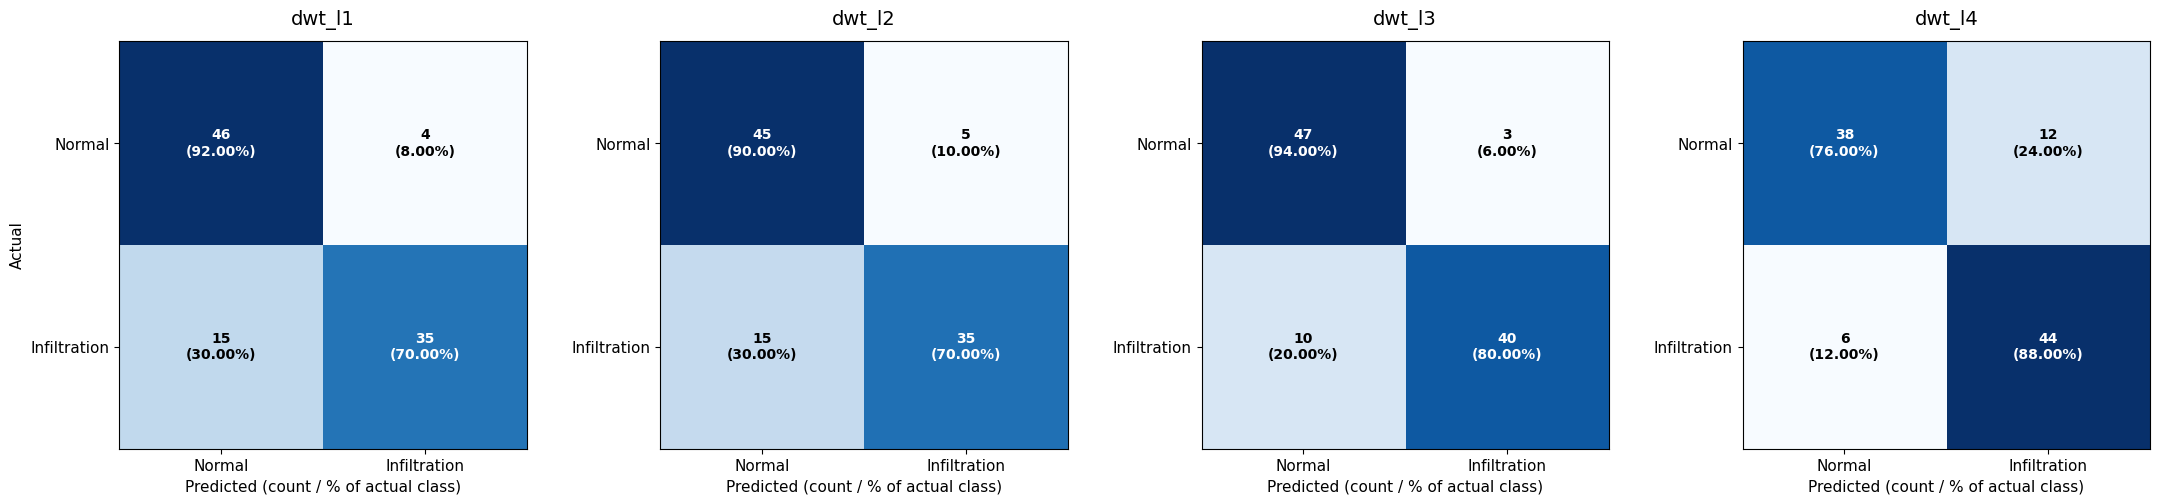

บันทึกภาพ Confusion Matrix เรียบร้อยแล้วที่ 'confusion_matrices_pure_dwt_L1_L4.png'


In [ ]:
import os
import cv2
import pywt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# -------------------------------------------------------------
# 1. ฟังก์ชัน DWT กรองสัญญาณรบกวนความถี่สูง (Wavelet: db1)
# -------------------------------------------------------------
dwt_threshold_ratios = {'L1': 0.05, 'L2': 0.10, 'L3': 0.20, 'L4': 0.35}

def apply_pure_dwt(img_gray_np, thresh_ratio=0.10):
    """แยกย่อยความถี่ด้วย 2D DWT และทำ Soft Thresholding บนรายละเอียดย่อย"""
    coeffs2 = pywt.dwt2(img_gray_np.astype(np.float32), 'db1')
    LL, (LH, HL, HH) = coeffs2

    # คำนวณขีดแบ่งเกณฑ์ (Threshold) จากค่าสัมประสิทธิ์สูงสุด
    max_coeff = np.max([np.abs(LH), np.abs(HL), np.abs(HH)])
    threshold = thresh_ratio * max_coeff

    # กรองความถี่สูงด้วย Soft Thresholding
    LH_t = pywt.threshold(LH, threshold, mode='soft')
    HL_t = pywt.threshold(HL, threshold, mode='soft')
    HH_t = pywt.threshold(HH, threshold, mode='soft')

    # สังเคราะห์ภาพย้อนกลับ (Inverse DWT)
    recon = pywt.idwt2((LL, (LH_t, HL_t, HH_t)), 'db1')
    return np.clip(recon, 0, 255).astype(np.uint8)

# -------------------------------------------------------------
# 2. Pre-process และบันทึกภาพลงแคช (Offline Caching)
# -------------------------------------------------------------
def cache_dwt_dataset(df_subset, subset_name):
    for lvl in ['L1', 'L2', 'L3', 'L4']:
        os.makedirs(f"/content/dwt_cache/{subset_name}/{lvl}", exist_ok=True)

    print(f"กำลังบันทึกแคช DWT สำหรับชุด {subset_name} ({len(df_subset)} ภาพ)...")
    for _, row in df_subset.iterrows():
        img_id = row['image_id']
        img_gray = cv2.imread(row['img_path'], cv2.IMREAD_GRAYSCALE)
        img_resized = cv2.resize(img_gray, (224, 224))

        for lvl, tr in dwt_threshold_ratios.items():
            denoised_dwt = apply_pure_dwt(img_resized, thresh_ratio=tr)
            save_path = f"/content/dwt_cache/{subset_name}/{lvl}/{img_id}.png"
            cv2.imwrite(save_path, denoised_dwt)

cache_dwt_dataset(train_df, "train")
cache_dwt_dataset(test_df, "test")
print("แคชชุดข้อมูล DWT L1 - L4 เสร็จสมบูรณ์!\n")

# -------------------------------------------------------------
# 3. Custom Dataset สำหรับอ่านภาพจากแคช DWT
# -------------------------------------------------------------
class CachedDWTCXRDataset(Dataset):
    def __init__(self, dataframe, subset_name="train", level='L1', transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.subset_name = subset_name
        self.level = level
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_id = self.df.loc[idx, 'image_id']
        cached_path = f"/content/dwt_cache/{self.subset_name}/{self.level}/{img_id}.png"
        image = Image.open(cached_path).convert('RGB')
        label = int(self.df.loc[idx, 'target'])

        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# -------------------------------------------------------------
# 4. ฝึกสอน ResNet-50 เปรียบเทียบ DWT (L1 - L4)
# -------------------------------------------------------------
filter_levels = ['L1', 'L2', 'L3', 'L4']
results = []
confusion_matrices = {}

print("========================================================")
print(" เริ่มการทดลองฝึกสอน Pure DWT Pipeline (L1 - L4)")
print("========================================================")

for level in filter_levels:
    print(f"\n>>> [กำลังเริ่มการทดลอง: Pure DWT {level}] <<<")

    lvl_train_loader = DataLoader(
        CachedDWTCXRDataset(train_df, "train", level=level, transform=train_transform),
        batch_size=32, shuffle=True, num_workers=2
    )
    lvl_test_loader = DataLoader(
        CachedDWTCXRDataset(test_df, "test", level=level, transform=val_test_transform),
        batch_size=32, shuffle=False, num_workers=2
    )

    # ควบคุมตัวแปรให้เป็น Fair Comparison (ResNet-50 Fixed Backbone)
    lvl_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    lvl_model.fc = nn.Linear(lvl_model.fc.in_features, 2)
    lvl_model = lvl_model.to(device)

    lvl_criterion = nn.CrossEntropyLoss()
    lvl_optimizer = torch.optim.Adam(lvl_model.parameters(), lr=1e-4)

    # ฝึกสอน 7 Epochs
    lvl_model.train()
    for epoch in range(7):
        running_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in lvl_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            lvl_optimizer.zero_grad()
            outputs = lvl_model(imgs)
            loss = lvl_criterion(outputs, lbls)
            loss.backward()
            lvl_optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == lbls.data).item()
            total += lbls.size(0)

        if (epoch + 1) in [1, 4, 7]:
            print(f"Epoch [{epoch+1:02d}/07] Loss: {running_loss/total:.4f} | Train Acc: {correct/total:.4f}")

    # บันทึก Checkpoint
    save_name = f"dwt_{level.lower()}_resnet50.pth"
    torch.save(lvl_model.state_dict(), save_name)

    # ทดสอบบน Balanced Test Set 100 ภาพ
    lvl_model.eval()
    all_preds, all_targets, all_probs = [], [], []
    with torch.no_grad():
        for imgs, lbls in lvl_test_loader:
            imgs = imgs.to(device)
            outputs = lvl_model(imgs)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(lbls.numpy())

    all_targets = np.array(all_targets)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    roc = roc_auc_score(all_targets, all_probs)

    results.append({
        'สภาวะการทดลอง': f'DWT {level}',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })

    confusion_matrices[level] = confusion_matrix(all_targets, all_preds)

# -------------------------------------------------------------
# 5. แสดงผลตารางสรุป Metric ทางการแพทย์
# -------------------------------------------------------------
df_results = pd.DataFrame(results)
print("\n" + "="*70)
print(" สรุปผลการประเมินการจำแนกโรคกลุ่ม Pure DWT (L1 - L4)")
print("="*70)
display(df_results.style.format({
    'Accuracy': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC': '{:.4f}'
}))

# -------------------------------------------------------------
# 6. พล็อต Confusion Matrices 4 ช่อง
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_labels = ['Normal', 'Infiltration']

for idx, level in enumerate(filter_levels):
    cm = confusion_matrices[level]
    ax = axes[idx]

    ax.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    ax.set_title(f'dwt_{level.lower()}', fontsize=14, pad=12)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels, fontsize=11)
    ax.set_yticklabels(class_labels, fontsize=11)
    ax.set_xlabel('Predicted (count / % of actual class)', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Actual', fontsize=11)

    for i in range(2):
        row_sum = cm[i].sum()
        for j in range(2):
            count = cm[i, j]
            pct = (count / row_sum * 100) if row_sum > 0 else 0
            text_color = "white" if count > (cm.max() / 2) else "black"
            ax.text(j, i, f"{count}\n({pct:.2f}%)", ha="center", va="center",
                    color=text_color, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices_pure_dwt_L1_L4.png', dpi=300)
plt.show()
print("บันทึกภาพ Confusion Matrix เรียบร้อยแล้วที่ 'confusion_matrices_pure_dwt_L1_L4.png'")